So what really is a machine learning model? Well, for starters we can treat a machine learning model like a black box to which we provide real world input (an image, a video etc) and this is encoded as a vector of numbers formed as the model input. The "box" maps the input to an output vector which is then translated to a real world prediction that us humans can understand better than the original vector output. 

Now that we've asserted that, let's look deeper into the black box. Let's think of a model that predicts the population of a country from its land area. The model acts like a mathematical equation that presents the average population as a function of land area. The model maps the input to the output from a family of equations where the curve (the specific equation used) is chosen using training data during what we call the training phase providing the model with pairs of input and output. Training the model is purely searching through the family of equations to find the one that best fits the training data (hence the term fitting equivalent to training). 

The pairs practically act as a supervisor during the training hence the term supervised learning. 

You may wonder whether unsupervised models exist. Unsupervised learning is simpler to describe. It's when a model is constructed from input data without the existence of output labels and so there can be no mapping from input to output like we followed in supervised learning, rather we aim to understand the structure of the data. There is also a third family called reinforcement learning, where a model learns by trial and error from rewards. Unsupervised and reinforcement learning deserve posts of their own, so I will leave them for the future and use supervised learning as our running example.

Let's finally get into some code to visualise the model with a very very simplistic example.

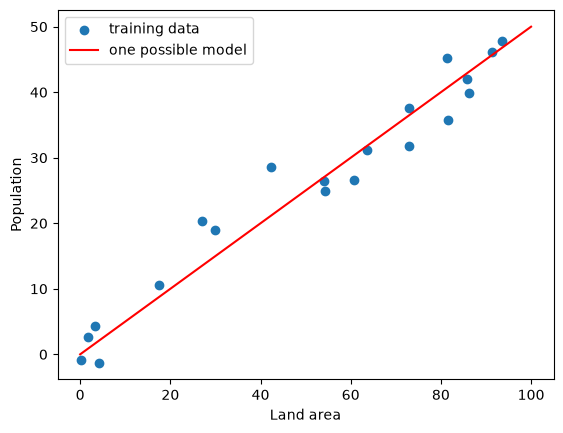

In [3]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
area = rng.uniform(0, 100, 20)
pop = 0.5 * area + rng.normal(0, 5, 20)

plt.scatter(area, pop, label="training data")
plt.plot([0, 100], [0, 50], color="red", label="one possible model")
plt.xlabel("Land area")
plt.ylabel("Population")
plt.legend()
plt.show()

The code is irrelevant to what we are trying to understand here so I will explain it in another post if you're interested. The basic idea though is that we are creating fake country data with 20 numbers ranging from 0-100 describing the land area of each fake country and the population is half the land area adjusted with random noise so it resembles real world data. The red line is  our model that makes the prediction which in this case is simply the line passing closest to the dots that resemble the countries.


Now you may already have thought that this line doesn't feel like it resembles quite perfectly the example. And so we introduce the term loss (that is measured by a loss function) which in machine learning is the metric that calculates how wrong a model's prediction is compared to the actual truth. On its own this number means little, but it lets us compare lines: the lower, the better

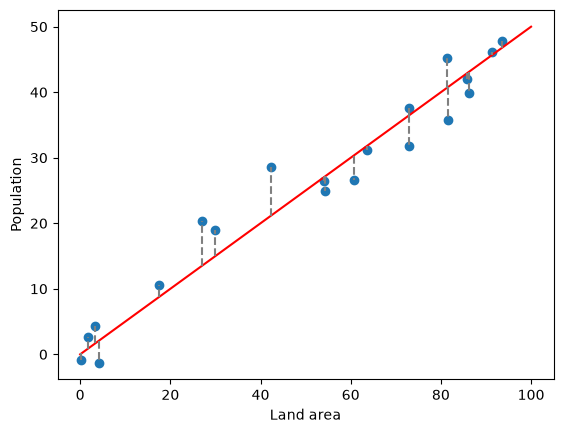

loss = 12.22


In [5]:
pred = 0.5 * area 
errors = pop - pred 
loss = (errors ** 2).mean() 

plt.scatter(area, pop) 
plt.plot([0, 100], [0, 50], color="red") 
plt.vlines(area, pred, pop, color="gray", linestyle="--") 
plt.xlabel("Land area")
plt.ylabel("Population")
plt.show()
print(f"loss = {loss:.2f}")


How do we know if a line is good? We measure how far it is from each dot. The average of these distances squared is our loss. Congratulations! You've just learned your first of many loss functions called the mean squared error with a scary looking mathematical formula that looks like this: 
<img src="loss_function.png" width="400">
where Yi in our case would be the real population, y hat would be the model's prediction for the country and N the number of countries taken into account. 

So now that we have understood what loss looks like it's easier to understand training as training is simply figuring out the line with the lowest loss. Basically, we try different models from the family of equations previously mentioned, with different slopes, so we test many slopes and choose the best one, the one with the lowest loss. The lowest point of the curve is at a slope of about 0.5, which is exactly how we generated the data.

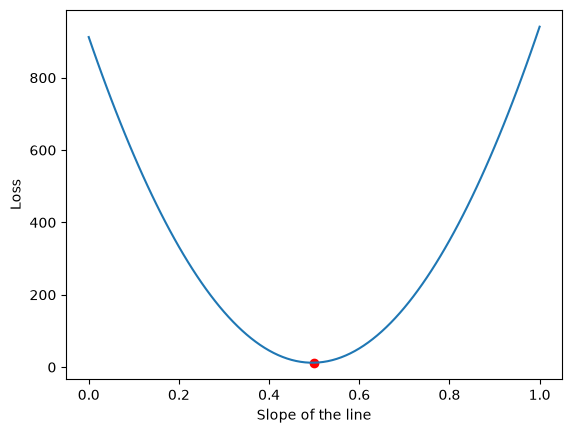

best slope = 0.50


In [4]:
slopes = np.linspace(0, 1, 101) 
losses = [((pop - w * area) ** 2).mean() for w in slopes] 
best = slopes[np.argmin(losses)]

plt.plot(slopes, losses) 
plt.scatter(best, min(losses), color="red") 
plt.xlabel("Slope of the line")
plt.ylabel("Loss")
plt.show()
print(f"best slope = {best:.2f}") 


The loss forms a valley, and training is simply finding its bottom. Real networks have millions of parameters, so they can’t try every combination. Instead they walk downhill step by step, which is called gradient descent.
That's it! We've successfully understood what the core idea behind machine learning and the basics that define it. In the next post we will build a simple real model that recognises handwritten digits (MNIST). 